# Coffee Quality: EDA and Modelling

A worked example of the machine learning workflow. We use the Arabica coffee quality dataset to predict each coffee's overall cupping score from its measured attributes, then check how well the model does. Treat this notebook as a reference for the structure of your own project.

## The Machine Learning Workflow

### Define the Business Goal

The stakeholder is a **green coffee buyer at a coffee importer**. Each season they review many Arabica lots and want to spend their time and budget on the most promising ones.

Estimate a coffee's overall **cupping score** from attributes known *before* a full tasting, so the buyer can shortlist which lots to taste, support price negotiations, and avoid spending cupping sessions on low-quality coffees.

The score depends on many attributes at once, so a model gives a faster and more consistent estimate than a manual rule of thumb.

The estimate should be close enough to be useful in practice, for example within a couple of points on the 0 to 100 scale.

In data science terms this is a **regression** problem: the target `total_cup_points` is a continuous number, and we measure the error with the **root mean squared error (RMSE)**, which is in the same units as the score (points).

### Get the Data

We load the cleaned Arabica dataset. It holds both the coffee attributes and the overall cupping score (`Total.Cup.Points`), which we will use as the target.

In [516]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.model_selection import cross_val_score, cross_validate, StratifiedKFold
from xgboost import XGBClassifier
import os
os.environ["PYDEVD_DISABLE_FILE_VALIDATION"] = "1"




In [517]:
df = pd.read_csv("data/ks-projects-201801.csv",encoding="latin-1")

In [518]:
df.head()

,ID,name,category,main_category,currency,deadline,goal,launched,pledged,state,backers,country,usd pledged,usd_pledged_real,usd_goal_real
0,1000002330,The Songs of Adelaide & Abullah,Poetry,Publishing,GBP,2015-10-09,1000.0,2015-08-11 12:12:28,0.0,failed,0,GB,0.0,0.0,1533.95
1,1000003930,Greeting From Earth: ZGAC Arts Capsule For ET,Narrative Film,Film & Video,USD,2017-11-01,30000.0,2017-09-02 04:43:57,2421.0,failed,15,US,100.0,2421.0,30000.00
2,1000004038,Where is Hank?,Narrative Film,Film & Video,USD,2013-02-26,45000.0,2013-01-12 00:20:50,220.0,failed,3,US,220.0,220.0,45000.00
3,1000007540,ToshiCapital Rekordz Needs Help to Complete Album,Music,Music,USD,2012-04-16,5000.0,2012-03-17 03:24:11,1.0,failed,1,US,1.0,1.0,5000.00
4,1000011046,Community Film Project: The Art of Neighborhoo...,Film & Video,Film & Video,USD,2015-08-29,19500.0,2015-07-04 08:35:03,1283.0,canceled,14,US,1283.0,1283.0,19500.00


In [519]:
df.state.value_counts()



state
failed        197719
successful    133956
canceled       38779
undefined       3562
live            2799
suspended       1846
Name: count, dtype: int64

In [520]:
df.nunique()

ID                  378661
name                375764
category               159
main_category           15
currency                14
deadline              3164
goal                  8353
launched            378089
pledged              62130
state                    6
backers               3963
country                 23
usd pledged          95455
usd_pledged_real    106065
usd_goal_real        50339
dtype: int64

In [521]:
def check_duplicates(data):
    has_dup = data.duplicated()
    n_dup = has_dup.sum()

    if n_dup > 0:
        print("Data has", n_dup, "duplicates")
    else:
        print("Data has no duplicates")


check_duplicates(df)

Data has no duplicates


In [522]:
df.isnull().sum()

ID                     0
name                   4
category               0
main_category          0
currency               0
deadline               0
goal                   0
launched               0
pledged                0
state                  0
backers                0
country                0
usd pledged         3797
usd_pledged_real       0
usd_goal_real          0
dtype: int64

<Axes: xlabel='pledged', ylabel='usd_pledged_real'>

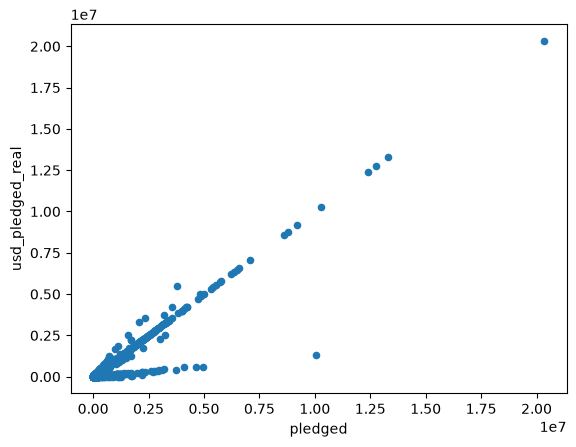

In [523]:
df.plot.scatter(x="pledged",y="usd_pledged_real")




In [524]:
df.currency.value_counts()

currency
USD    295365
GBP     34132
EUR     17405
CAD     14962
AUD      7950
SEK      1788
MXN      1752
NZD      1475
DKK      1129
CHF       768
NOK       722
HKD       618
SGD       555
JPY        40
Name: count, dtype: int64

<Axes: xlabel='pledged', ylabel='usd_pledged_real'>

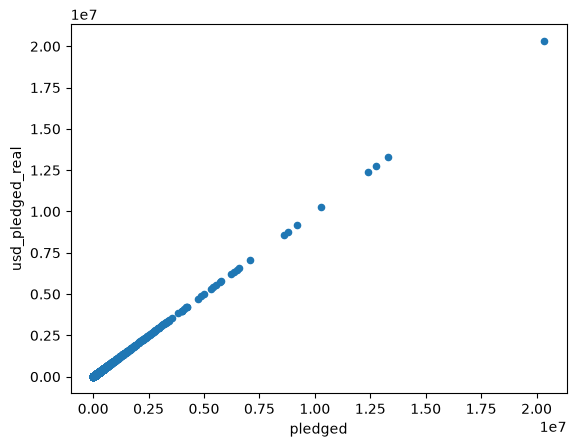

In [525]:
df[df["currency"]=="USD"].plot.scatter(x="pledged",y="usd_pledged_real")

<Axes: xlabel='currency', ylabel='country'>

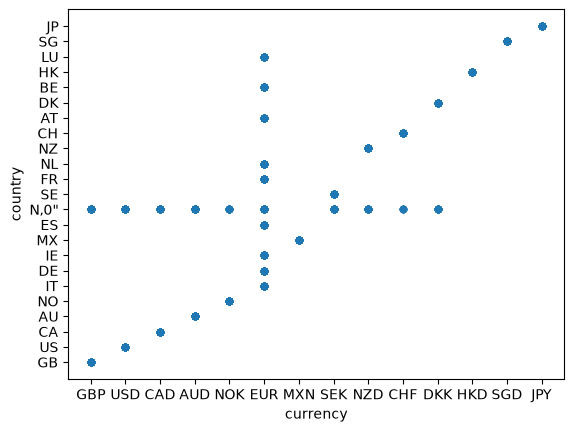

In [526]:
df.plot.scatter(x="currency",y="country")




In [527]:
df.country.value_counts()

country
US      292627
GB       33672
CA       14756
AU        7839
DE        4171
N,0"      3797
FR        2939
IT        2878
NL        2868
ES        2276
SE        1757
MX        1752
NZ        1447
DK        1113
IE         811
CH         761
NO         708
HK         618
BE         617
AT         597
SG         555
LU          62
JP          40
Name: count, dtype: int64

In [528]:
df['name_length'] = df['name'].str.len()
df=df.drop(columns=["goal","ID","pledged","usd pledged","currency","name"])
df.name_length.nunique()

99

In [529]:
df.isnull().sum()

category            0
main_category       0
deadline            0
launched            0
state               0
backers             0
country             0
usd_pledged_real    0
usd_goal_real       0
name_length         4
dtype: int64

In [530]:

df=df.dropna(subset="name_length")#drop the 4 nan values
df.isnull().sum()

category            0
main_category       0
deadline            0
launched            0
state               0
backers             0
country             0
usd_pledged_real    0
usd_goal_real       0
name_length         0
dtype: int64

In [531]:
df.state.value_counts()


state
failed        197716
successful    133956
canceled       38779
undefined       3562
live            2799
suspended       1845
Name: count, dtype: int64

In [532]:
df["state"]=df["state"].replace("canceled","failed")
df=df.query("state in ['successful','failed']")
df.state.value_counts()




state
failed        236495
successful    133956
Name: count, dtype: int64

In [533]:
df["deadline"]=pd.to_datetime(df["deadline"])
df["launched"]=pd.to_datetime(df["launched"])
df.dtypes

category                       str
main_category                  str
deadline            datetime64[us]
launched            datetime64[us]
state                          str
backers                      int64
country                        str
usd_pledged_real           float64
usd_goal_real              float64
name_length                float64
dtype: object

In [534]:
df["duration_days"] = (df["deadline"] - df["launched"]).dt.days
df["launch_month"] = df["launched"].dt.month
df["launch_weekday"] = df["launched"].dt.dayofweek
df["launch_year"] = df["launched"].dt.year

df = df.drop(columns=["launched", "deadline"])
df.head()

,category,main_category,state,backers,country,usd_pledged_real,usd_goal_real,name_length,duration_days,launch_month,launch_weekday,launch_year
0,Poetry,Publishing,failed,0,GB,0.0,1533.95,31.0,58,8,1,2015
1,Narrative Film,Film & Video,failed,15,US,2421.0,30000.00,45.0,59,9,5,2017
2,Narrative Film,Film & Video,failed,3,US,220.0,45000.00,14.0,44,1,5,2013
3,Music,Music,failed,1,US,1.0,5000.00,49.0,29,3,5,2012
4,Film & Video,Film & Video,failed,14,US,1283.0,19500.00,58.0,55,7,5,2015


In [535]:
df.launch_year.value_counts()

launch_year
2015    74199
2014    66724
2016    56411
2017    49185
2013    44791
2012    41109
2011    26192
2010    10503
2009     1329
1970        6
2018        2
Name: count, dtype: int64

159

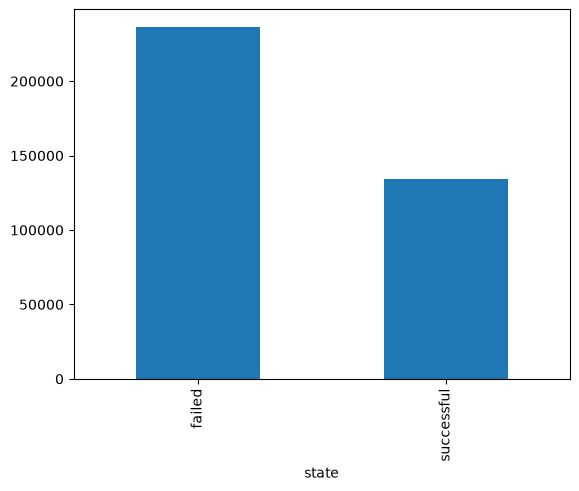

In [536]:
df["state"].value_counts().plot.bar()
df.dtypes
df["category"].nunique()

In [537]:
df["state"].value_counts(normalize=True)*100

state
failed        63.839752
successful    36.160248
Name: proportion, dtype: float64

<Axes: ylabel='main_category'>

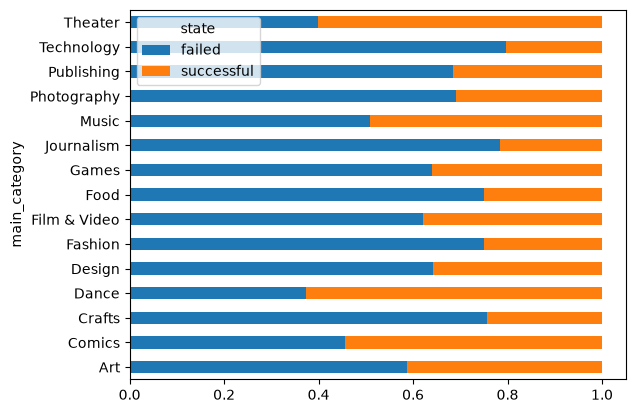

In [538]:
pd.crosstab(df["main_category"],df["state"],normalize="index").plot.barh(stacked=True)

<Axes: >

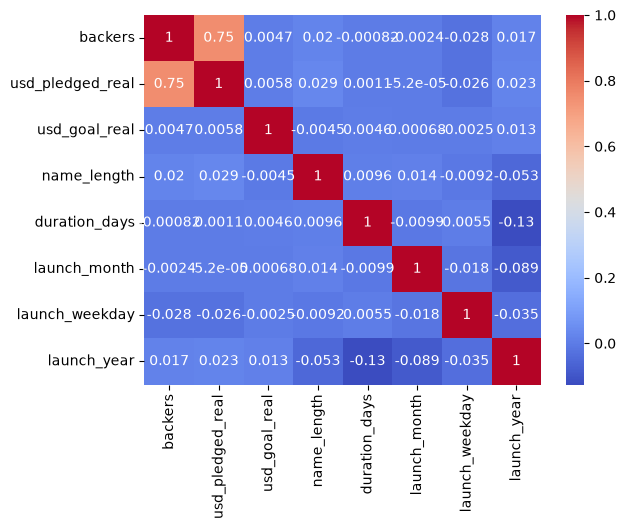

In [539]:
sns.heatmap(df.select_dtypes("number").corr(), annot=True, cmap="coolwarm")

<Axes: ylabel='launch_month'>

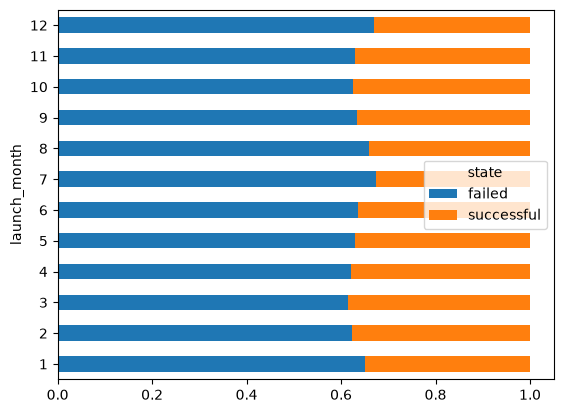

In [540]:
pd.crosstab(df["launch_month"],df["state"],normalize="index").plot.barh(stacked=True)

           success_rate  count
name_bin                      
(0, 10]        0.310429  18381
(10, 20]       0.301801  67624
(20, 30]       0.346417  74266
(30, 40]       0.383311  66617
(40, 50]       0.405270  60461
(50, 60]       0.385114  79940
(60, 100]      0.407970   3162


<Axes: xlabel='name_bin', ylabel='Success rate'>

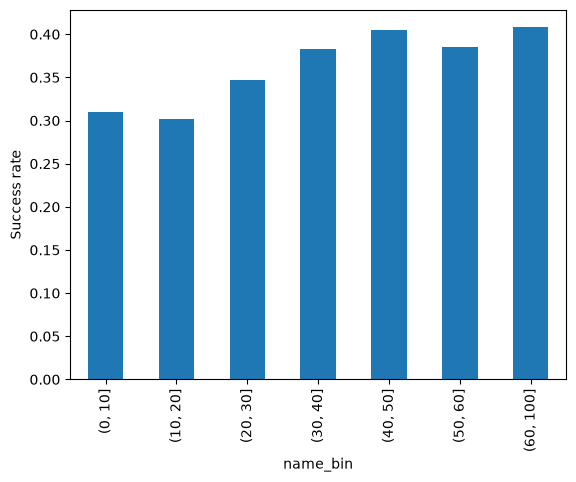

In [541]:
df['name_bin'] = pd.cut(df['name_length'], bins=[0, 10, 20, 30, 40, 50, 60, 100])

summary = df.groupby('name_bin', observed=True).agg(
    success_rate=('state', lambda s: (s == 'successful').mean()),
    count=('state', 'size')
)
print(summary)
summary['success_rate'].plot(kind='bar', ylabel='Success rate')

<Axes: ylabel='launch_weekday'>

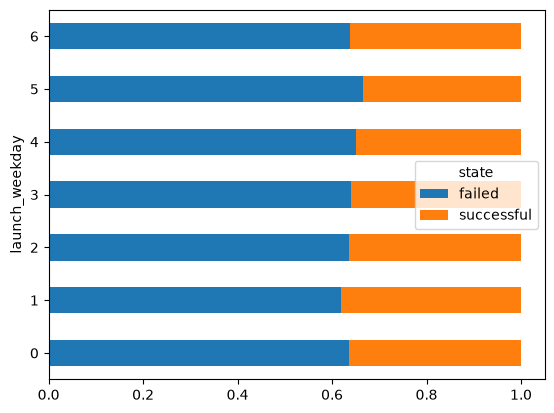

In [542]:
pd.crosstab(df["launch_weekday"],df["state"],normalize="index").plot.barh(stacked=True)

<Axes: ylabel='launch_year'>

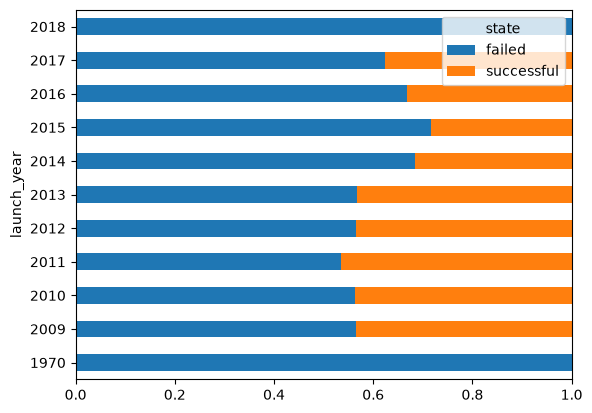

In [543]:
pd.crosstab(df["launch_year"],df["state"],normalize="index").plot.barh(stacked=True)

In [544]:
df.head()

,category,main_category,state,backers,country,usd_pledged_real,usd_goal_real,name_length,duration_days,launch_month,launch_weekday,launch_year,name_bin
0,Poetry,Publishing,failed,0,GB,0.0,1533.95,31.0,58,8,1,2015,"(30, 40]"
1,Narrative Film,Film & Video,failed,15,US,2421.0,30000.00,45.0,59,9,5,2017,"(40, 50]"
2,Narrative Film,Film & Video,failed,3,US,220.0,45000.00,14.0,44,1,5,2013,"(10, 20]"
3,Music,Music,failed,1,US,1.0,5000.00,49.0,29,3,5,2012,"(40, 50]"
4,Film & Video,Film & Video,failed,14,US,1283.0,19500.00,58.0,55,7,5,2015,"(50, 60]"


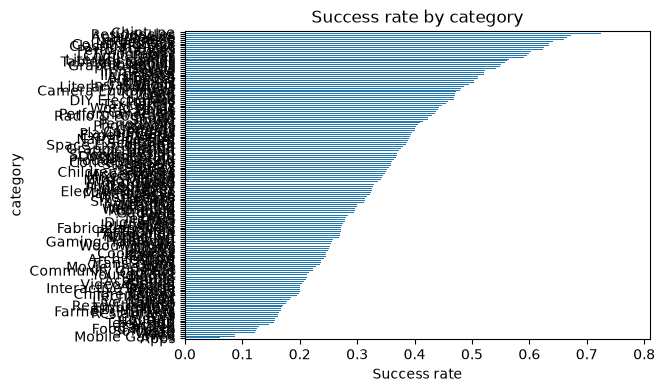

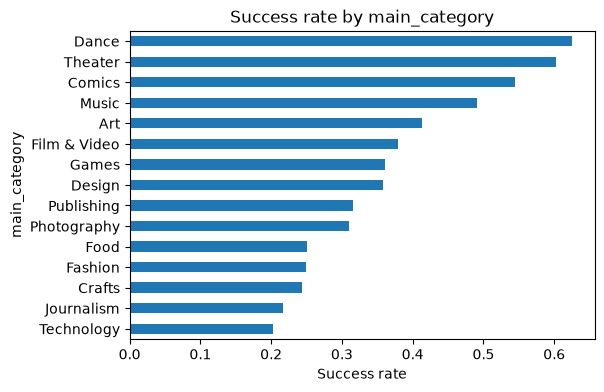

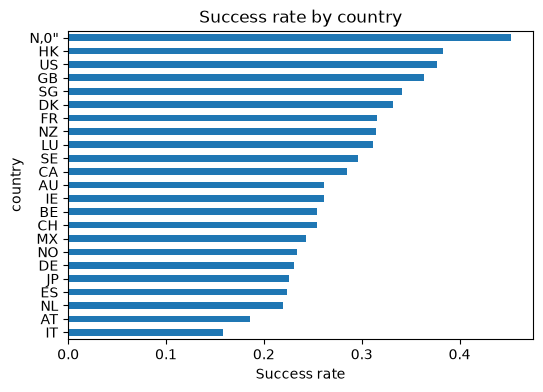

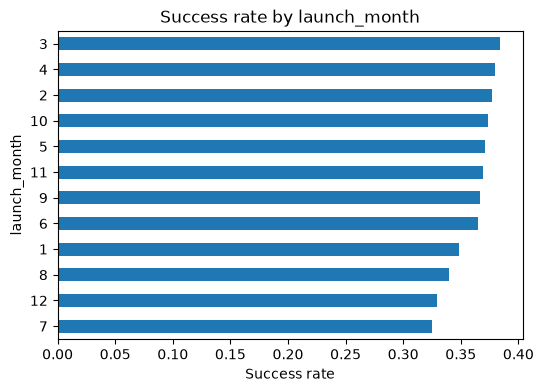

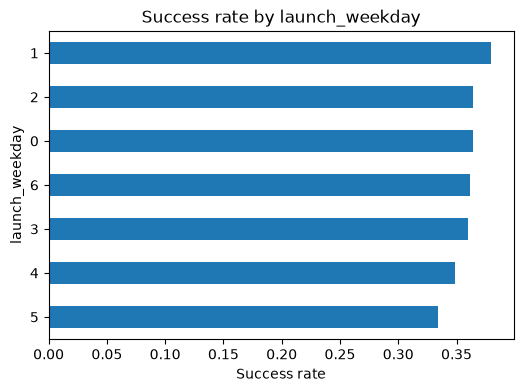

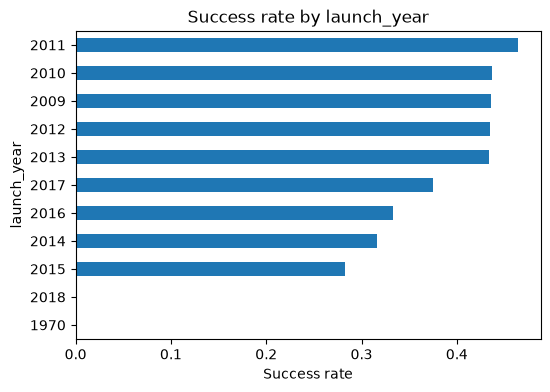

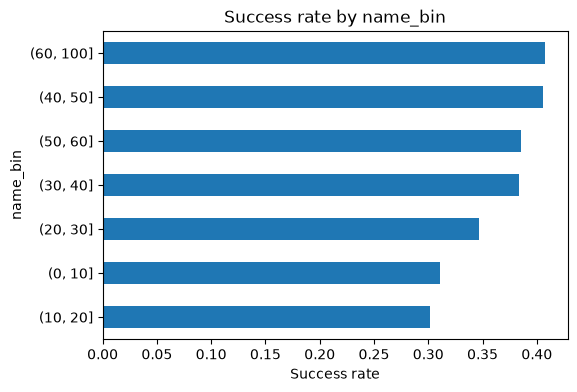

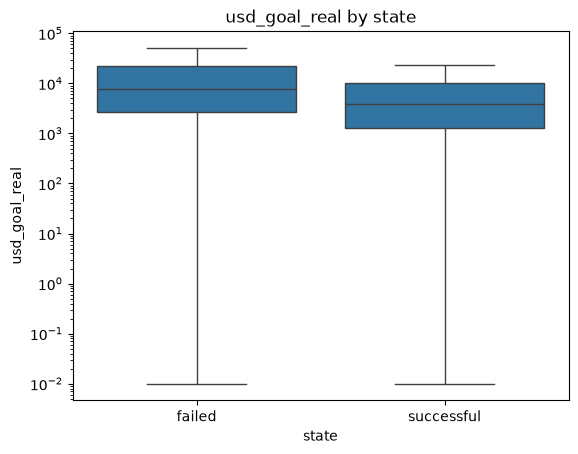

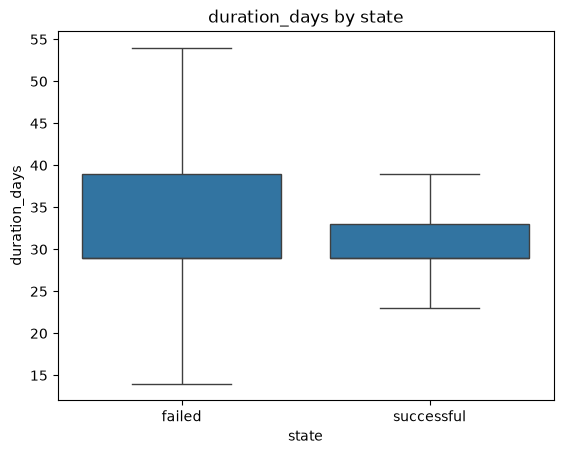

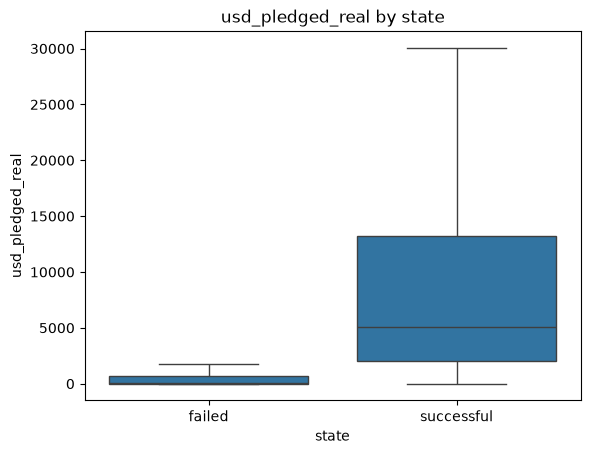

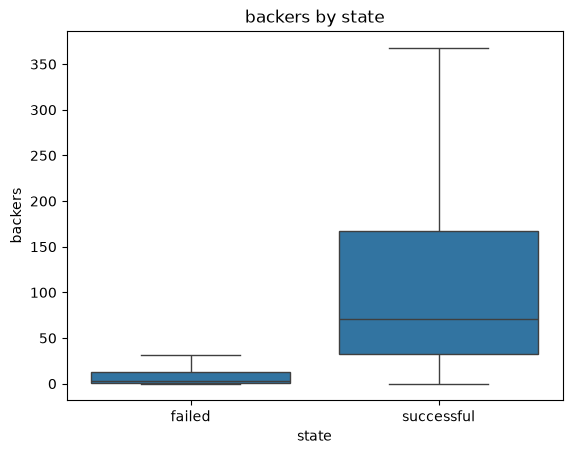

In [545]:
df["success"] = (df["state"] == "successful").astype(int)

cat_cols = ["category","main_category", "country", "launch_month", "launch_weekday", "launch_year","name_bin"]
num_cols = ["usd_goal_real", "duration_days","usd_pledged_real","backers"]

# Categorical: success rate per group
for col in cat_cols:
    rate = df.groupby(col)["success"].mean().sort_values()
    rate.plot.barh(figsize=(6, 4), title=f"Success rate by {col}")
    plt.xlabel("Success rate")
    plt.show()

# Numeric: distribution for failed vs successful
for col in num_cols:
    sns.boxplot(data=df, x="state", y=col, showfliers=False)
    plt.yscale("log" if col == "usd_goal_real" else "linear")
    plt.title(f"{col} by state")
    plt.show()

In [546]:
df[(df["usd_goal_real"] <100) & (df["state"]=="failed")]

,category,main_category,state,backers,country,usd_pledged_real,usd_goal_real,name_length,duration_days,launch_month,launch_weekday,launch_year,name_bin,success
23,Drinks,Food,failed,3,NO,6.29,65.55,49.0,29,1,0,2015,"(40, 50]",0
288,Fiction,Publishing,failed,6,GB,42.81,64.87,55.0,29,6,4,2017,"(50, 60]",0
306,Farmer's Markets,Food,failed,2,CA,5.50,13.76,19.0,29,7,2,2014,"(10, 20]",0
720,Cookbooks,Food,failed,3,GB,20.03,16.69,50.0,29,7,4,2014,"(40, 50]",0
763,Bacon,Food,failed,0,US,0.00,20.00,31.0,29,7,3,2014,"(30, 40]",0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
377820,Mixed Media,Art,failed,0,US,0.00,50.00,43.0,29,7,2,2012,"(40, 50]",0
377956,Video Games,Games,failed,4,US,4.00,50.00,11.0,6,11,3,2013,"(10, 20]",0
378006,Graphic Design,Design,failed,0,US,0.00,50.00,54.0,29,5,0,2015,"(50, 60]",0
378342,Drama,Film & Video,failed,0,US,0.00,1.00,18.0,30,3,3,2016,"(10, 20]",0


In [547]:
df = df.drop(columns=["backers", "usd_pledged_real","success","main_category"])
df.head()


,category,state,country,usd_goal_real,name_length,duration_days,launch_month,launch_weekday,launch_year,name_bin
0,Poetry,failed,GB,1533.95,31.0,58,8,1,2015,"(30, 40]"
1,Narrative Film,failed,US,30000.00,45.0,59,9,5,2017,"(40, 50]"
2,Narrative Film,failed,US,45000.00,14.0,44,1,5,2013,"(10, 20]"
3,Music,failed,US,5000.00,49.0,29,3,5,2012,"(40, 50]"
4,Film & Video,failed,US,19500.00,58.0,55,7,5,2015,"(50, 60]"


In [548]:
from sklearn.model_selection import train_test_split
X=df.drop(columns="state")
y = df['state'].map({'failed': 0, 'successful': 1})
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20,stratify=y,random_state=42)




In [549]:
# Heuristic baseline: ignore the features, always predict the mean training score
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score,roc_auc_score

dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)
pred = dummy.predict(X_test)

print("Accuracy:", accuracy_score(y_test, pred))
print("ROC_AUC:", roc_auc_score(y_test, pred))

Accuracy: 0.6384041246575157
ROC_AUC: 0.5


In [550]:


cat_cols = ["category", "country", "launch_month", "launch_weekday", "launch_year","name_bin"]
goal_col = ["usd_goal_real"]
scale_cols = ["duration_days"]

preprocess = make_column_transformer(
    (OneHotEncoder(handle_unknown="ignore"), cat_cols),
    (make_pipeline(FunctionTransformer(np.log1p), StandardScaler()), goal_col),
    (StandardScaler(), scale_cols),
)
cvst = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
param_grid1 = {
    'logisticregression__C': [0.001, 0.01, 0.1, 1, 10, 100],
    'logisticregression__class_weight': [None, 'balanced'],
}

pipe = make_pipeline(preprocess, LogisticRegression(solver="saga",max_iter=1000, random_state=42))

grid = GridSearchCV(pipe, param_grid1, cv=cvst, scoring="roc_auc", n_jobs=-1)
pipe.fit(X_train, y_train)
#print(grid.best_params_, grid.best_score_)
#print(classification_report(y_train,grid.predict(X_train)))
#print(roc_auc_score(y_train,grid.predict(X_train)))
print(classification_report(y_train,pipe.predict(X_train)))
print(roc_auc_score(y_train,pipe.predict(X_train)))


/Users/firasharb/Desktop/notebooks/ML_project/kickstarter_project/.venv/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


              precision    recall  f1-score   support

           0       0.72      0.85      0.78    189195
           1       0.61      0.41      0.49    107165

    accuracy                           0.69    296360
   macro avg       0.67      0.63      0.64    296360
weighted avg       0.68      0.69      0.68    296360

0.631334742913317


In [551]:
pipeforest = make_pipeline(preprocess,
                  RandomForestClassifier(random_state=42,n_estimators=200,max_depth=15,min_samples_leaf=20,class_weight="balanced",n_jobs=-1))
param_grid2 = {
    'randomforestclassifier__max_depth': [3, 5, 8, None],
    'randomforestclassifier__min_samples_leaf': [1, 3, 5, 10],
    'randomforestclassifier__class_weight': [None, 'balanced'],
}
#grid2 = GridSearchCV(pipeforest, param_grid2, cv=cvst, scoring="roc_auc", n_jobs=-1)
#grid2.fit(X_train, y_train)
#print(grid2.best_params_, grid2.best_score_)
#print(classification_report(y_train,grid2.predict(X_train)))
#pipeforest.fit(X_train, y_train)
#print(classification_report(y_train,pipeforest.predict(X_train)))
#print(roc_auc_score(y_train,pipeforest.predict(X_train)))
scores = cross_val_score(pipeforest, X_train, y_train,
                         cv=cvst, scoring="roc_auc", n_jobs=-1)
print(scores)          
print(scores.mean())   
print(scores.std()) 



[0.71978665 0.7254943  0.72076275 0.71932671 0.72062093]
0.7211982677204611
0.0022124338809638346


In [552]:
pipetree = make_pipeline(preprocess,
                  DecisionTreeClassifier(random_state=42,max_depth=10,min_samples_leaf=50,class_weight="balanced"))
param_grid3 = {
    'decisiontreeclassifier__max_depth': [2, 3, 4, 5, 6, 8],
    'decisiontreeclassifier__min_samples_leaf': [1, 5, 10, 20],
    'decisiontreeclassifier__criterion': ['gini', 'entropy'],
    'decisiontreeclassifier__class_weight': [None, 'balanced'],
}

#grid3 = GridSearchCV(pipetree, param_grid3, cv=cvst, scoring="roc_auc", n_jobs=-1)
#grid3.fit(X_train, y_train)
#print(grid3.best_params_, grid3.best_score_)
#print(classification_report(y_train,grid3.predict(X_train)))
#pipetree.fit(X_train, y_train)
scores = cross_val_score(pipetree, X_train, y_train,
                         cv=cvst, scoring="roc_auc", n_jobs=-1)
#print(classification_report(y_train,pipetree.predict(X_train)))
#print(roc_auc_score(y_train,pipetree.predict(X_train)))
print(scores)          
print(scores.mean())   
print(scores.std()) 


[0.69602743 0.69917906 0.69509884 0.69044169 0.69434564]
0.6950185321505361
0.0028190272637794184


In [553]:
XGBOOST = make_pipeline(preprocess,
                  XGBClassifier(random_state=42,n_estimators=500,learning_rate=0.5,max_depth=6,eval_metric="auc",n_jobs=-1))
param_grid5 = {
    'xgbclassifier__n_estimators': [100, 200, 400],
    'xgbclassifier__learning_rate': [0.01, 0.05, 0.1],
    'xgbclassifier__max_depth': [2, 3, 4],
    'xgbclassifier__subsample': [0.8, 1.0],
    'xgbclassifier__scale_pos_weight': [1, 1.9],
}

#grid5 = GridSearchCV(XGBOOST, param_grid5, cv=cvst, scoring="roc_auc", n_jobs=-1)
#grid5.fit(X_train, y_train)
#print(grid5.best_params_, grid5.best_score_)
#print(classification_report(y_train,grid5.predict(X_train)))
#XGBOOST.fit(X_train, y_train)
scores = cross_val_score(XGBOOST, X_train, y_train,
                         cv=cvst, scoring="roc_auc", n_jobs=-1)

print(scores)          
print(scores.mean())   
print(scores.std())  
#print(classification_report(y_train,XGBOOST.predict(X_train)))
#print(roc_auc_score(y_train,XGBOOST.predict(X_train)))


[0.74210458 0.74328837 0.74342906 0.74121196 0.74278241]
0.7425632776751002
0.0008197324211617074


In [554]:

XGBOOST.fit(X_train, y_train)
print(classification_report(y_test,XGBOOST.predict(X_test)))
print(roc_auc_score(y_test, XGBOOST.predict_proba(X_test)[:, 1]))

              precision    recall  f1-score   support

           0       0.74      0.83      0.78     47300
           1       0.62      0.49      0.55     26791

    accuracy                           0.71     74091
   macro avg       0.68      0.66      0.66     74091
weighted avg       0.70      0.71      0.70     74091

0.7488777707132882


## References & Further Reading

- [**LinearRegression (scikit-learn)**](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html): the model trained in this notebook.
- [**train_test_split (scikit-learn)**](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html): how the held-out test set is created.
- [**root_mean_squared_error (scikit-learn)**](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.root_mean_squared_error.html): the metric used to evaluate the model and the baseline.
- [**Common pitfalls and recommended practices (scikit-learn)**](https://scikit-learn.org/stable/common_pitfalls.html): how data leakage happens and how to avoid it.
- [**Coffee Quality Database**](https://github.com/jldbc/coffee-quality-database): the source of the dataset used here.